<a href="https://colab.research.google.com/github/sivabada2/ReDocly-APIFirst/blob/main/Course_End_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Applied Data Science with Python**
Course-End Project 01





# **Introduction**
#### AAL, established in 2000, is a well-known brand in Australia, particularly recognized for its clothing business. It has opened branches in various states, metropolises, and tier-1 and tier-2 cities across the country.

#### The brand caters to all age groups, from kids to the elderly.
#### Currently experiencing a surge in business, AAL is actively pursuing expansion opportunities. To facilitate informed investment decisions, the CEO has assigned the responsibility to the head of AAL’s sales and marketing (S&M) department. The specific tasks include:
#### Identify the states that are generating the highest revenues.
#### Develop sales programs for states with lower revenues. The head of sales and marketing has requested your assistance with this task.
#### Analyze the sales data of the company for the fourth quarter in Australia, examining it on a state-by-state basis. Provide insights to assist the company in making data-driven decisions for the upcoming year.





# **Data Preparation**

*   Data Wrangling
*   Data Analysis
*   Data Visualization
*   Report Generation

## Data Wrangling

#### 1. Ensure that the data is clean and free from any missing or incorrect entries. Inspect the data manually to identify missing or incorrect information using the functions isna() and notna().

In [1]:
#read the csv file
import pandas as pd
df = pd.read_csv('/content/AusApparalSales4thQrt2020.csv')
display(df.head())

,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500


In [2]:
#verify the result
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    7560 non-null   object
 1   Time    7560 non-null   object
 2   State   7560 non-null   object
 3   Group   7560 non-null   object
 4   Unit    7560 non-null   int64 
 5   Sales   7560 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 354.5+ KB


#### 2. Based on your knowledge of data analytics, include your recommendations for treating missing and incorrect data (dropping the null values or filling them).

In [3]:
import pandas as pd
df = pd.read_csv('/content/AusApparalSales4thQrt2020.csv')

# Check for missing values
df.isnull().sum()

# Incorrect data
print("Unique values for 'State':", df['State'].unique())
print("Unique values for 'Group':", df['Group'].unique())
print("Unique values for 'Time':", df['Time'].unique())

# Check numerical columns for incorrect data
print("\nDescriptive statistics for 'Unit' column:")
display(df['Unit'].describe())
print("\nValues in 'Unit' less than or equal to 0:", df[df['Unit'] <= 0]['Unit'].count())

print("\nDescriptive statistics for 'Sales' column:")
display(df['Sales'].describe())
print("\nValues in 'Sales' less than or equal to 0:", df[df['Sales'] <= 0]['Sales'].count())

# Impute
# Remove leading/trailing spaces from object columns
for col in ['State', 'Group', 'Time']:
    df[col] = df[col].str.strip()
print("\nAfter stripping spaces:")
print("Unique values for 'State':", df['State'].unique())
print("Unique values for 'Group':", df['Group'].unique())
print("Unique values for 'Time':", df['Time'].unique())

# Convert 'Date' and 'Time' columns to datetime objects
df['Date'] = pd.to_datetime(df['Date'], format='%d-%b-%Y')
# For 'Time', we'll extract the hour for potential analysis, assuming typical time values like 'Morning', 'Afternoon', 'Evening'
# For now, let's just confirm the 'Date' conversion. 'Time' column is categorical, so converting it to a datetime object directly is not straightforward for its current values.
# We can create a new feature from 'Time' if needed, e.g., mapping to hours.
print("\nData types after converting 'Date':")
display(df[['Date', 'Time']].info())

# Dropping
# Drop duplicate rows
df.drop_duplicates(inplace=True)
print(f"\nDataFrame shape after dropping duplicates: {df.shape}")

Unique values for 'State': [' WA' ' NT' ' SA' ' VIC' ' QLD' ' NSW' ' TAS']
Unique values for 'Group': [' Kids' ' Men' ' Women' ' Seniors']
Unique values for 'Time': [' Morning' ' Afternoon' ' Evening']

Descriptive statistics for 'Unit' column:


,Unit
count,7560.000000
mean,18.005423
std,12.901403
min,2.000000
25%,8.000000
50%,14.000000
75%,26.000000
max,65.000000



Values in 'Unit' less than or equal to 0: 0

Descriptive statistics for 'Sales' column:


,Sales
count,7560.000000
mean,45013.558201
std,32253.506944
min,5000.000000
25%,20000.000000
50%,35000.000000
75%,65000.000000
max,162500.000000



Values in 'Sales' less than or equal to 0: 0

After stripping spaces:
Unique values for 'State': ['WA' 'NT' 'SA' 'VIC' 'QLD' 'NSW' 'TAS']
Unique values for 'Group': ['Kids' 'Men' 'Women' 'Seniors']
Unique values for 'Time': ['Morning' 'Afternoon' 'Evening']

Data types after converting 'Date':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    7560 non-null   datetime64[ns]
 1   Time    7560 non-null   object        
dtypes: datetime64[ns](1), object(1)
memory usage: 118.3+ KB


None


DataFrame shape after dropping duplicates: (7560, 6)


In [4]:
# Verify your result
# Check for duplicate rows
duplicate_rows = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicate_rows}")



Number of duplicate rows: 0


#### 3. Choose a suitable data wrangling technique either data standardization or normalization. Execute the preferred normalization method and present the resulting data. (Normalization is the preferred approach for this problem.)

Normalization, specifically Min-Max scaling, transforms features by scaling each feature to a given range, typically 0 to 1. This technique is useful when the features have different ranges and scales, preventing features with larger values from dominating the learning process of certain models.

In [4]:
# Normalization / Standardization
# Apply Min-Max Normalization to 'Unit' and 'Sales' columns
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df[['Unit_Normalized', 'Sales_Normalized']] = scaler.fit_transform(df[['Unit', 'Sales']])

print("Original 'Unit' statistics:")
display(df['Unit'].describe())

print("\nNormalized 'Unit' statistics:")
display(df['Unit_Normalized'].describe())

print("\nOriginal 'Sales' statistics:")
display(df['Sales'].describe())

print("\nNormalized 'Sales' statistics:")
display(df['Sales_Normalized'].describe())


Original 'Unit' statistics:


,Unit
count,7560.000000
mean,18.005423
std,12.901403
min,2.000000
25%,8.000000
50%,14.000000
75%,26.000000
max,65.000000



Normalized 'Unit' statistics:


,Unit_Normalized
count,7560.000000
mean,0.254054
std,0.204784
min,0.000000
25%,0.095238
50%,0.190476
75%,0.380952
max,1.000000



Original 'Sales' statistics:


,Sales
count,7560.000000
mean,45013.558201
std,32253.506944
min,5000.000000
25%,20000.000000
50%,35000.000000
75%,65000.000000
max,162500.000000



Normalized 'Sales' statistics:


,Sales_Normalized
count,7560.000000
mean,0.254054
std,0.204784
min,0.000000
25%,0.095238
50%,0.190476
75%,0.380952
max,1.000000


In [5]:
# Verify your result
print("Min and Max of Normalized 'Unit':", df['Unit_Normalized'].min(), df['Unit_Normalized'].max())
print("Min and Max of Normalized 'Sales':", df['Sales_Normalized'].min(), df['Sales_Normalized'].max())


Min and Max of Normalized 'Unit': 0.0 0.9999999999999999
Min and Max of Normalized 'Sales': 0.0 1.0


#### 4. Share your insights regarding the application of the GroupBy() function for either data chunking or merging, and offer a recommendation based on your analysis.

In [6]:
# Groupby ?
# Group data by 'State' and 'Group' to analyze total sales and units
aggregated_data = df.groupby(['State', 'Group']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Units=('Unit', 'sum')
).reset_index()
display(aggregated_data.head())

,State,Group,Total_Sales,Total_Units
0,NSW,Kids,18587500,7435
1,NSW,Men,19022500,7609
2,NSW,Seniors,18187500,7275
3,NSW,Women,19172500,7669
4,NT,Kids,5700000,2280


## Data Analysis

#### 1. Perform descriptive statistical analysis on the data in the Sales and Unit columns. Utilize techniques such as mean, median, mode, and standard deviation for this analysis.

In [8]:
# Basic Descriptive Statistics
print("Descriptive Statistics for 'Unit' column:")
display(df['Unit'].describe())
print("Median of 'Unit':", df['Unit'].median())
print("Mode of 'Unit':", df['Unit'].mode().tolist())

print("\nDescriptive Statistics for 'Sales' column:")
display(df['Sales'].describe())
print("Median of 'Sales':", df['Sales'].median())
print("Mode of 'Sales':", df['Sales'].mode().tolist())

# Additional (missing) Statistics reporting
print("\nAdditional Statistics for 'Unit' column:")
print("Variance of 'Unit':", df['Unit'].var())
print("Skewness of 'Unit':", df['Unit'].skew())
print("Kurtosis of 'Unit':", df['Unit'].kurt())

print("\nAdditional Statistics for 'Sales' column:")
print("Variance of 'Sales':", df['Sales'].var())
print("Skewness of 'Sales':", df['Sales'].skew())
print("Kurtosis of 'Sales':", df['Sales'].kurt())

Descriptive Statistics for 'Unit' column:


,Unit
count,7560.000000
mean,18.005423
std,12.901403
min,2.000000
25%,8.000000
50%,14.000000
75%,26.000000
max,65.000000


Median of 'Unit': 14.0
Mode of 'Unit': [9]

Descriptive Statistics for 'Sales' column:


,Sales
count,7560.000000
mean,45013.558201
std,32253.506944
min,5000.000000
25%,20000.000000
50%,35000.000000
75%,65000.000000
max,162500.000000


Median of 'Sales': 35000.0
Mode of 'Sales': [22500]

Additional Statistics for 'Unit' column:
Variance of 'Unit': 166.4461936295156
Skewness of 'Unit': 1.0855501535060819
Kurtosis of 'Unit': 0.6614172266616092

Additional Statistics for 'Sales' column:
Variance of 'Sales': 1040288710.1844833
Skewness of 'Sales': 1.0855501535060816
Kurtosis of 'Sales': 0.6614172266616096


#### 2. Identify the group with the highest sales and the group with the lowest sales based on the data provided.

In [9]:
# Extend Statistical Reporting

# Identify group with the highest sales
highest_sales_group = aggregated_data.loc[aggregated_data['Total_Sales'].idxmax()]
print("\nGroup with the Highest Sales:")
display(highest_sales_group)

# Identify group with the lowest sales
lowest_sales_group = aggregated_data.loc[aggregated_data['Total_Sales'].idxmin()]
print("\nGroup with the Lowest Sales:")
display(lowest_sales_group)


Group with the Highest Sales:


,23
State,VIC
Group,Women
Total_Sales,26482500
Total_Units,10593



Group with the Lowest Sales:


,27
State,WA
Group,Women
Total_Sales,5262500
Total_Units,2105


#### 3. Identify the group with the highest and lowest sales based on the data provided.

In [24]:
# What is the difference from the above statement

from IPython.display import Markdown, display
display(Markdown('**Difference from the previous cell:**'))
display(Markdown('**There is no difference in the stated task. \
Both prompts ask to identify the group with the highest and lowest sales based on the provided data.**'))

print("##The task in this cell is identical to the task completed in the previous cell (`WEspqBkI6G63`).")

# Cell `WEspqBkI6G63` already identified and displayed:
# *   **Group with the Highest Sales:**
#     *   State: VIC
#     *   Group: Women
#     *   Total_Sales: 26,482,500
#     *   Total_Units: 10,593

# *   **Group with the Lowest Sales:**
#     *   State: WA
#     *   Group: Women
#     *   Total_Sales: 5,262,500
#     *   Total_Units: 2,105



**Difference from the previous cell:**

**There is no difference in the stated task. Both prompts ask to identify the group with the highest and lowest sales based on the provided data.**

##The task in this cell is identical to the task completed in the previous cell (`WEspqBkI6G63`).


#### 4. Generate weekly, monthly, and quarterly reports to document and present the results of the analysis conducted.

In [26]:
# Extend the above analysis on 3 different time based groupings.

import pandas as pd

# Ensure 'Date' column is datetime type
df['Date'] = pd.to_datetime(df['Date'])

# Extract week, month, and quarter
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)
df['Month'] = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.quarter

# Aggregate data by week
weekly_sales = df.groupby(['Week', 'State', 'Group']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Units=('Unit', 'sum')
).reset_index()
print("\nWeekly Sales Analysis (first 5 rows):")
display(weekly_sales.head())

# Aggregate data by month
monthly_sales = df.groupby(['Month', 'State', 'Group']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Units=('Unit', 'sum')
).reset_index()
print("\nMonthly Sales Analysis (first 5 rows):")
display(monthly_sales.head())

# Aggregate data by quarter
quarterly_sales = df.groupby(['Quarter', 'State', 'Group']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Units=('Unit', 'sum')
).reset_index()
print("\nQuarterly Sales Analysis (first 5 rows):")
display(quarterly_sales.head())


Weekly Sales Analysis (first 5 rows):


,Week,State,Group,Total_Sales,Total_Units
0,40,NSW,Kids,867500,347
1,40,NSW,Men,837500,335
2,40,NSW,Seniors,737500,295
3,40,NSW,Women,940000,376
4,40,NT,Kids,277500,111



Monthly Sales Analysis (first 5 rows):


,Month,State,Group,Total_Sales,Total_Units
0,10,NSW,Kids,6340000,2536
1,10,NSW,Men,6270000,2508
2,10,NSW,Seniors,5915000,2366
3,10,NSW,Women,6482500,2593
4,10,NT,Kids,2140000,856



Quarterly Sales Analysis (first 5 rows):


,Quarter,State,Group,Total_Sales,Total_Units
0,4,NSW,Kids,18587500,7435
1,4,NSW,Men,19022500,7609
2,4,NSW,Seniors,18187500,7275
3,4,NSW,Women,19172500,7669
4,4,NT,Kids,5700000,2280


## Data Visualization

#### Use suitable data visualization libraries to construct a dashboard for the head of sales and marketing. The dashboard should encompass key parameters:

#### 1a. State-wise sales analysis for different demographic groups (kids, women, men, and seniors).

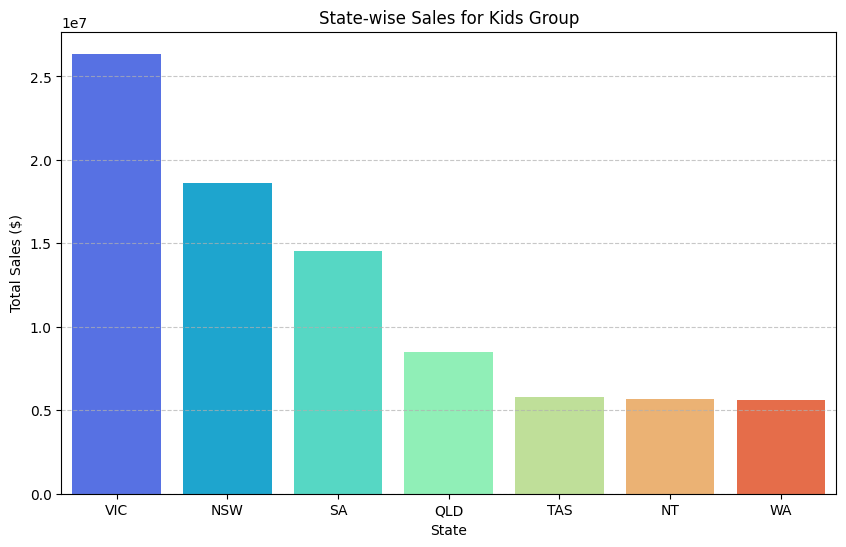

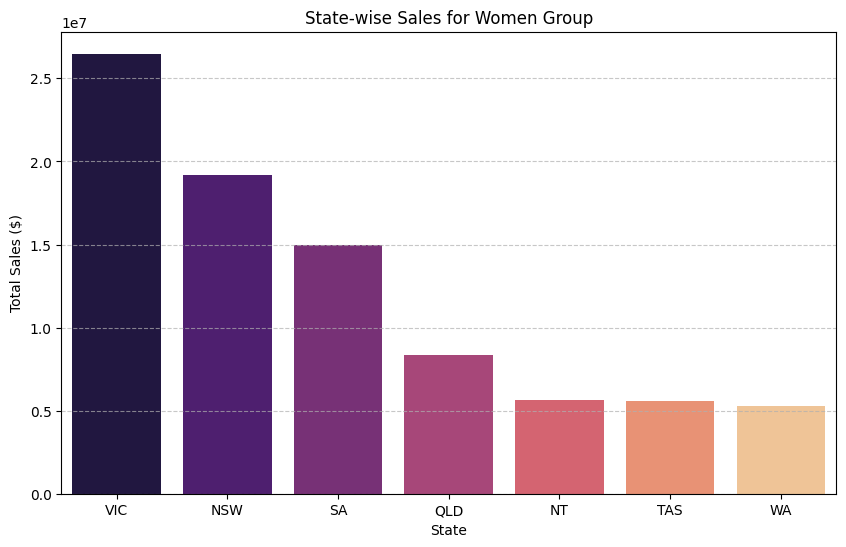

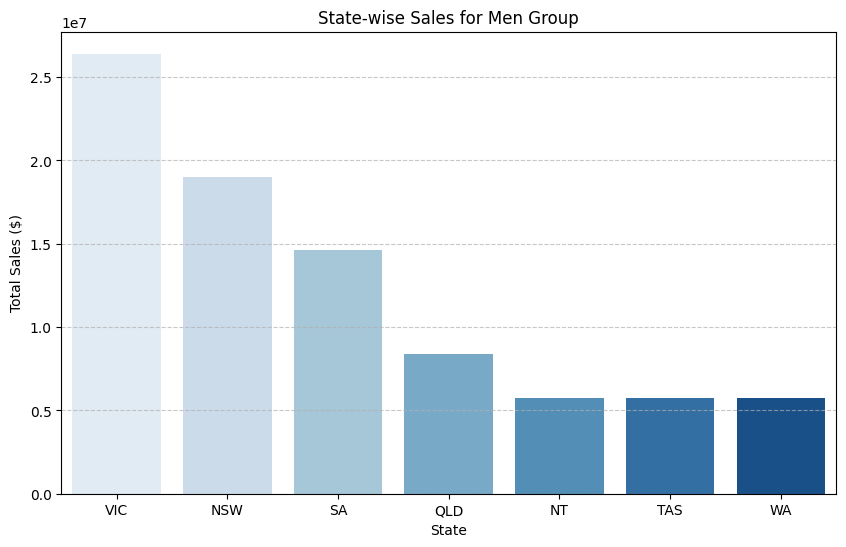

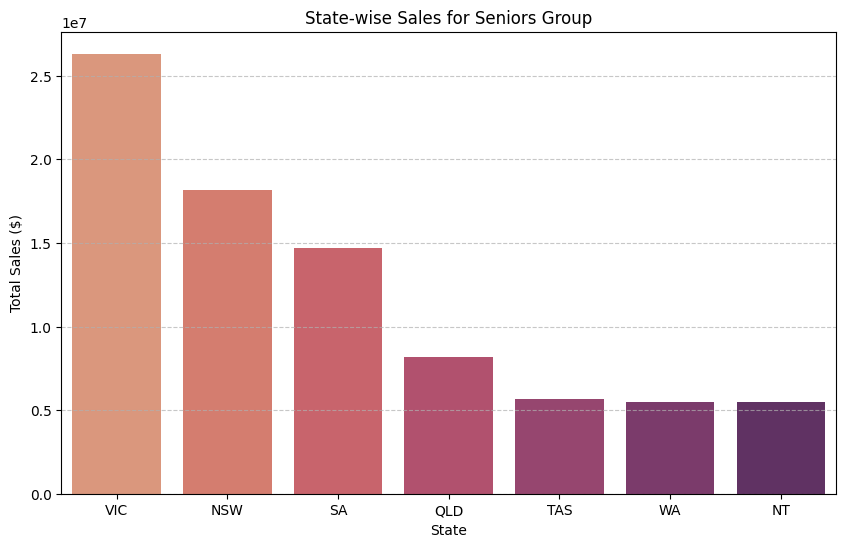

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# State - Kids
# Filter data for 'Kids' group
kids_sales = aggregated_data[aggregated_data['Group'] == 'Kids']

# Sort by Total_Sales for better visualization
kids_sales_sorted = kids_sales.sort_values(by='Total_Sales', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='State', y='Total_Sales', data=kids_sales_sorted, palette='rainbow', hue='State', legend=False)
plt.title('State-wise Sales for Kids Group')
plt.xlabel('State')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# State - Women
# Filter data for 'Women' group
women_sales = aggregated_data[aggregated_data['Group'] == 'Women']

# Sort by Total_Sales for better visualization
women_sales_sorted = women_sales.sort_values(by='Total_Sales', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='State', y='Total_Sales', data=women_sales_sorted, palette='magma', hue='State', legend=False)
plt.title('State-wise Sales for Women Group')
plt.xlabel('State')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# State - Men
# Filter data for 'Men' group
men_sales = aggregated_data[aggregated_data['Group'] == 'Men']

# Sort by Total_Sales for better visualization
men_sales_sorted = men_sales.sort_values(by='Total_Sales', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='State', y='Total_Sales', data=men_sales_sorted, palette='Blues', hue='State', legend=False)
plt.title('State-wise Sales for Men Group')
plt.xlabel('State')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# State - Seniors
# Filter data for 'Seniors' group
seniors_sales = aggregated_data[aggregated_data['Group'] == 'Seniors']

# Sort by Total_Sales for better visualization
seniors_sales_sorted = seniors_sales.sort_values(by='Total_Sales', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='State', y='Total_Sales', data=seniors_sales_sorted, palette='flare', hue='State', legend=False)
plt.title('State-wise Sales for Seniors Group')
plt.xlabel('State')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### 1b. Group-wise sales analysis (Kids, Women, Men, and Seniors) across various states.

In [38]:
# Kids - State
kids_group_sales = aggregated_data[aggregated_data['Group'] == 'Kids']
print("\nSales and Units for Kids Group across various States:")
display(kids_group_sales)

# Women - State
women_group_sales = aggregated_data[aggregated_data['Group'] == 'Women']
print("\nSales and Units for Women Group across various States:")
display(women_group_sales)

# Men - State
men_group_sales = aggregated_data[aggregated_data['Group'] == 'Men']
print("\nSales and Units for Men Group across various States:")
display(men_group_sales)


# Seniors - State
seniors_group_sales = aggregated_data[aggregated_data['Group'] == 'Seniors']
print("\nSales and Units for Seniors Group across various States:")
display(seniors_group_sales)


Sales and Units for Kids Group across various States:


,State,Group,Total_Sales,Total_Units
0,NSW,Kids,18587500,7435
4,NT,Kids,5700000,2280
8,QLD,Kids,8510000,3404
12,SA,Kids,14515000,5806
16,TAS,Kids,5775000,2310
20,VIC,Kids,26360000,10544
24,WA,Kids,5625000,2250



Sales and Units for Women Group across various States:


,State,Group,Total_Sales,Total_Units
3,NSW,Women,19172500,7669
7,NT,Women,5652500,2261
11,QLD,Women,8325000,3330
15,SA,Women,14970000,5988
19,TAS,Women,5577500,2231
23,VIC,Women,26482500,10593
27,WA,Women,5262500,2105



Sales and Units for Men Group across various States:


,State,Group,Total_Sales,Total_Units
1,NSW,Men,19022500,7609
5,NT,Men,5762500,2305
9,QLD,Men,8392500,3357
13,SA,Men,14655000,5862
17,TAS,Men,5757500,2303
21,VIC,Men,26407500,10563
25,WA,Men,5752500,2301



Sales and Units for Seniors Group across various States:


,State,Group,Total_Sales,Total_Units
2,NSW,Seniors,18187500,7275
6,NT,Seniors,5465000,2186
10,QLD,Seniors,8190000,3276
14,SA,Seniors,14717500,5887
18,TAS,Seniors,5650000,2260
22,VIC,Seniors,26315000,10526
26,WA,Seniors,5512500,2205


#### 1c. Time-of-the-day analysis: Identify peak and off-peak sales periods to facilitate strategic planning for S&M teams. This information aids in designing programs like hyper-personalization and Next Best Offers to enhance sales.

In [42]:
# Morning - Peak/Off Peak hours
morning_sales = df[df['Time'] == 'Morning']
morning_sales_daily = morning_sales.groupby('Date').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Units=('Unit', 'sum')
).reset_index()
print("\nMorning Sales Analysis (Daily):")
display(morning_sales_daily.head())

# Afternoon - Peak/Off Peak hours
afternoon_sales = df[df['Time'] == 'Afternoon']
afternoon_sales_daily = afternoon_sales.groupby('Date').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Units=('Unit', 'sum')
).reset_index()
print("\nAfternoon Sales Analysis (Daily):")
display(afternoon_sales_daily.head())

# Evening - Peak/Off Peak hours
evening_sales = df[df['Time'] == 'Evening']
evening_sales_daily = evening_sales.groupby('Date').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Units=('Unit', 'sum')
).reset_index()
print("\nEvening Sales Analysis (Daily):")
display(evening_sales_daily.head())



Morning Sales Analysis (Daily):


,Date,Total_Sales,Total_Units
0,2020-10-01,1225000,490
1,2020-10-02,1277500,511
2,2020-10-03,1455000,582
3,2020-10-04,1225000,490
4,2020-10-05,1295000,518



Afternoon Sales Analysis (Daily):


,Date,Total_Sales,Total_Units
0,2020-10-01,1212500,485
1,2020-10-02,1275000,510
2,2020-10-03,1137500,455
3,2020-10-04,1190000,476
4,2020-10-05,1237500,495



Evening Sales Analysis (Daily):


,Date,Total_Sales,Total_Units
0,2020-10-01,1282500,513
1,2020-10-02,1162500,465
2,2020-10-03,1297500,519
3,2020-10-04,1305000,522
4,2020-10-05,1330000,532


#### 2. Ensure the visualization is clear and accessible for effective decision-making by the head of sales and marketing (S&M). The dashboard must contain daily, weekly, monthly, and quarterly charts.

In [ ]:
# Demographics vs State - Peak vs Non Peak


#### 3. Include your recommendation and indicate why you are choosing the recommended visualization package.

In [ ]:
# Visualization comparisons

## Report Generation

#### 1. Use **JupyterLab Notebook** for generating reports, which includes tasks such as data wrangling, analysis, and visualization. Please note that JupyterLab enables you to integrate code seamlessly with graphs and plots.

#### 2. Use **Markdown** in suitable places while presenting your report.

#### 3. Use suitable graphs, plots, and analysis reports in the report, along with recommendations. Note that various aspects of analysis require different graphs and plots.

#### 3a. Use a **box plot** for descriptive statistics.

#### 3b. Use the **Seaborn** distribution plot for any other statistical plotting.

# Conclusion

#### 1. Paragraph - Describe your data

#### 2. Paragraph - Explain your process

#### 3. Paragraph - Justify your result

# Task
Analyze the provided sales data for AAL for the fourth quarter in Australia, examining it on a state-by-state basis. The goal is to identify states generating the highest revenues, develop sales programs for states with lower revenues, and provide insights to assist the company in making data-driven decisions for the upcoming year. This involves data wrangling (cleaning, handling missing/incorrect data, normalization), descriptive statistical analysis, identifying highest/lowest sales groups, and generating weekly, monthly, and quarterly sales reports. Finally, visualize the data to create a dashboard for the head of sales and marketing, encompassing state-wise sales analysis for different demographic groups, group-wise sales analysis across states, and time-of-the-day analysis (peak/off-peak periods). The visualization should be clear and accessible, including daily, weekly, monthly, and quarterly charts, and suitable visualization libraries should be recommended. The entire process should be documented in a JupyterLab Notebook using Markdown, graphs, plots, and analysis reports, along with recommendations and a conclusion summarizing the data, process, and results.

## Plot Daily Sales by Time of Day and Group

### Subtask:
Generate bar plots showing daily total sales for 'Morning', 'Afternoon', and 'Evening' periods for each demographic group (Kids, Women, Men, Seniors). Each plot will display daily sales trends for a specific group and time of day, helping to identify peak and off-peak hours within the day.


**Reasoning**:
To visualize daily sales for each demographic group across different times of the day, I need to first aggregate the sales data by 'Date', 'Time', and 'Group'. This will provide the necessary data structure for plotting the daily sales trends for each combination of group and time of day.



In [43]:
daily_sales_by_time_and_group = df.groupby(['Date', 'Time', 'Group']).agg(
    Total_Sales=('Sales', 'sum')
).reset_index()

display(daily_sales_by_time_and_group.head())


,Date,Time,Group,Total_Sales
0,2020-10-01,Afternoon,Kids,320000
1,2020-10-01,Afternoon,Men,282500
2,2020-10-01,Afternoon,Seniors,342500
3,2020-10-01,Afternoon,Women,267500
4,2020-10-01,Evening,Kids,267500


**Reasoning**:
Generate line plots to visualize daily sales trends for each demographic group, separated by time of day, as this is the most effective way to show trends over time and identify peak/off-peak periods clearly.



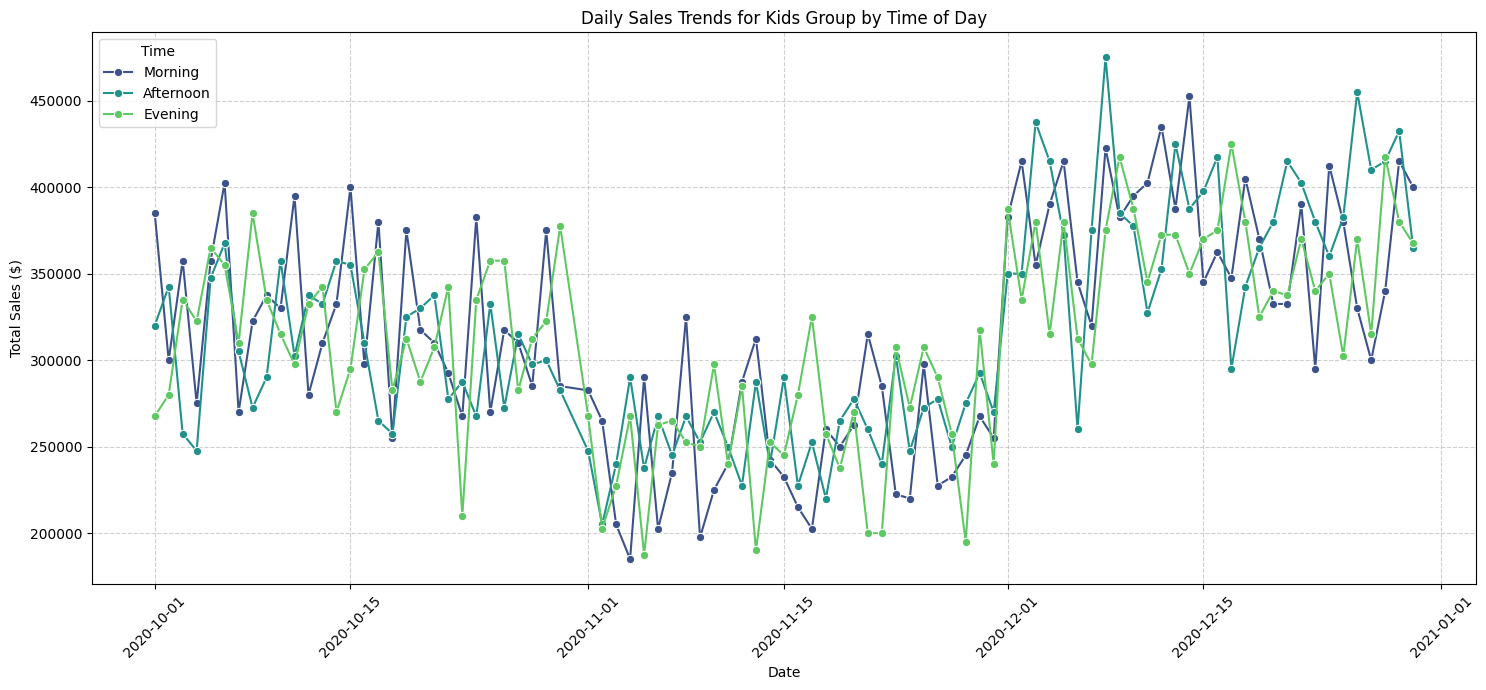

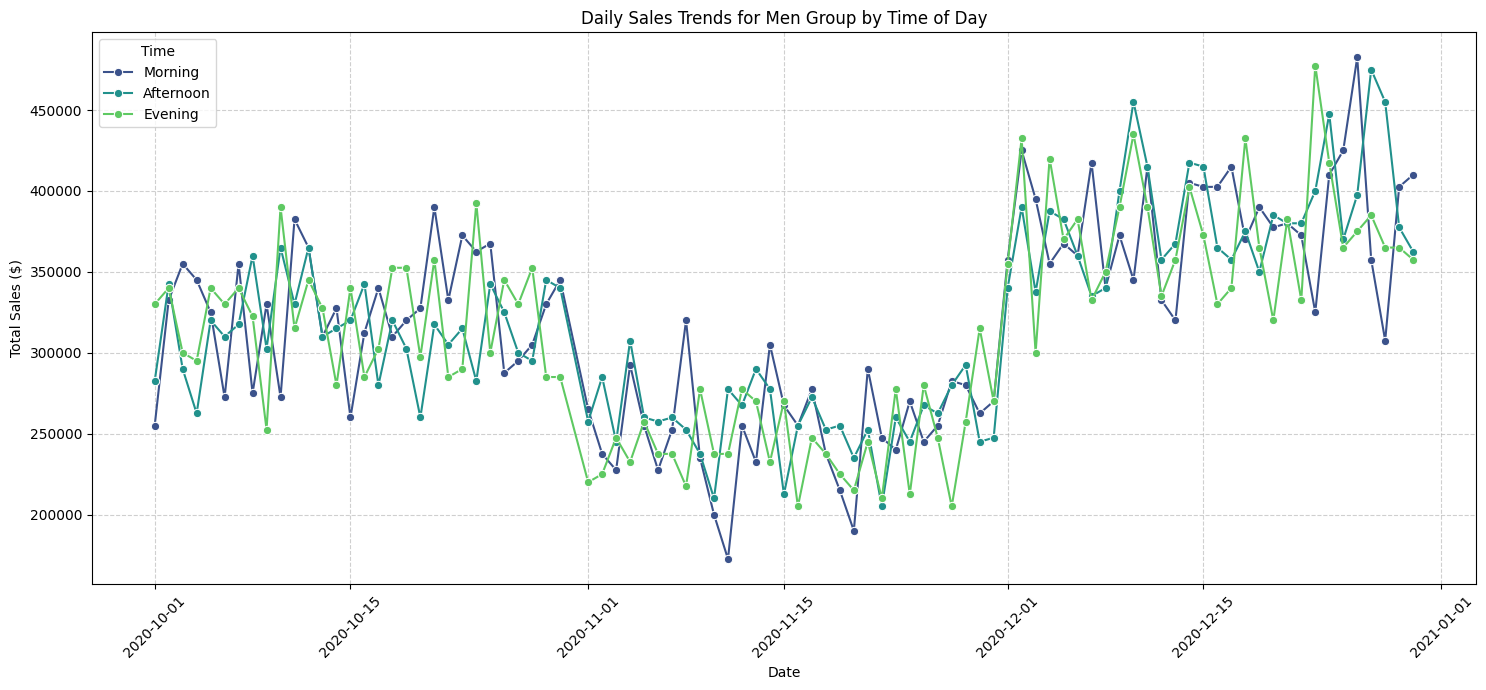

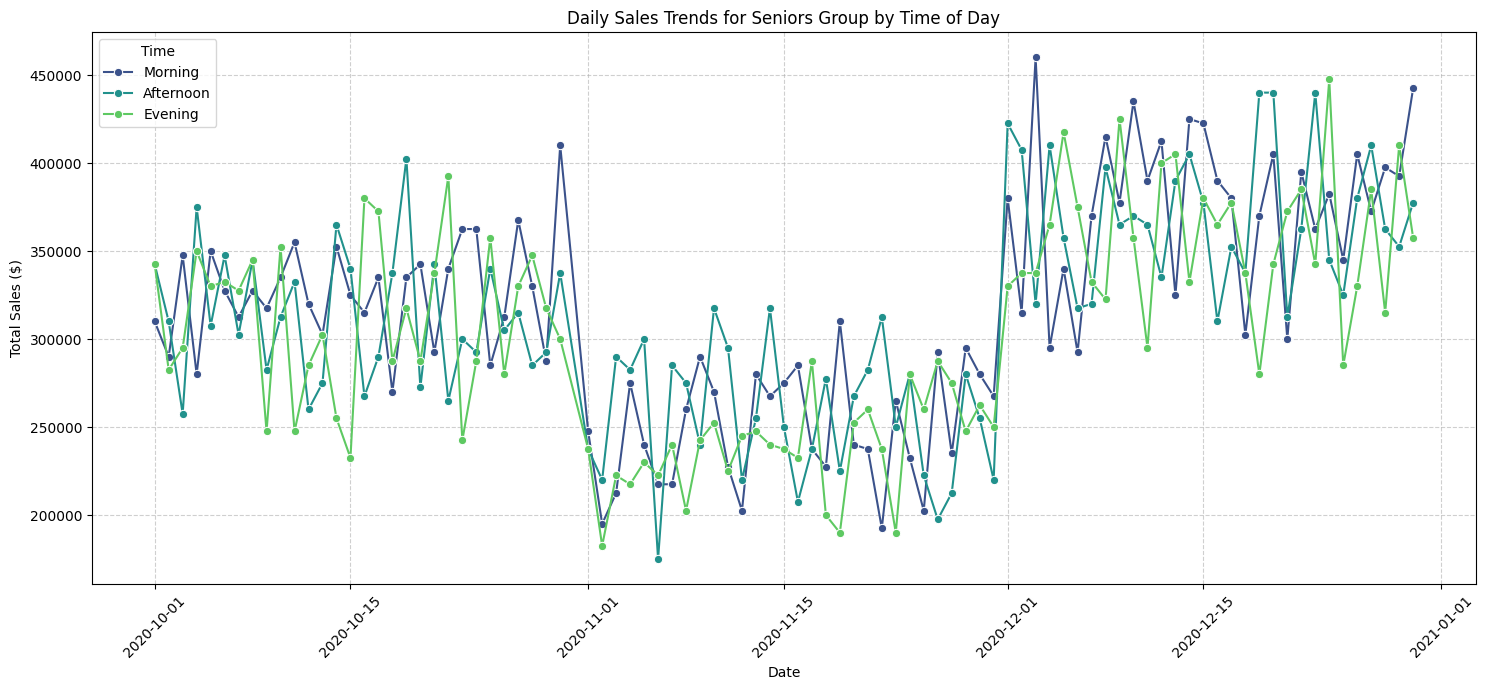

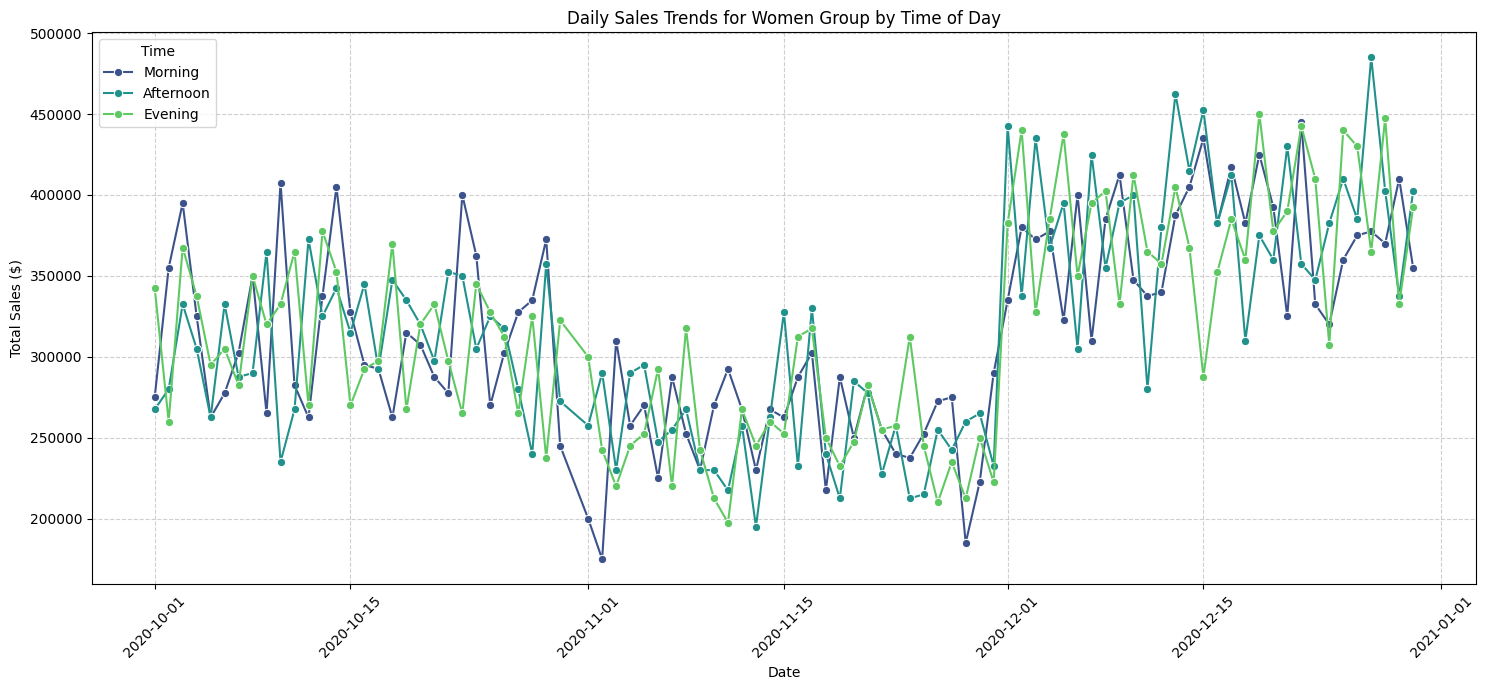

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get unique groups and times for iteration
groups = daily_sales_by_time_and_group['Group'].unique()
times = daily_sales_by_time_and_group['Time'].unique()

# Sort times for consistent plotting order (e.g., Morning, Afternoon, Evening)
time_order = ['Morning', 'Afternoon', 'Evening']
times_sorted = [t for t in time_order if t in times]

for group in groups:
    plt.figure(figsize=(15, 7))
    sns.lineplot(data=daily_sales_by_time_and_group[daily_sales_by_time_and_group['Group'] == group],
                 x='Date',
                 y='Total_Sales',
                 hue='Time',
                 palette='viridis',
                 hue_order=times_sorted,
                 marker='o') # Added markers for individual daily points
    plt.title(f'Daily Sales Trends for {group} Group by Time of Day')
    plt.xlabel('Date')
    plt.ylabel('Total Sales ($)')
    plt.xticks(rotation=45)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

## Plot Weekly Sales by Group and State

### Subtask:
Create line plots to visualize weekly sales trends for each demographic group, broken down by state. This will use the `weekly_sales` DataFrame to show performance and patterns over the weeks.


**Reasoning**:
Generate line plots to visualize weekly sales trends for each demographic group across different states, as specified in the instructions. This will provide a clear overview of weekly performance patterns for each state within every group.



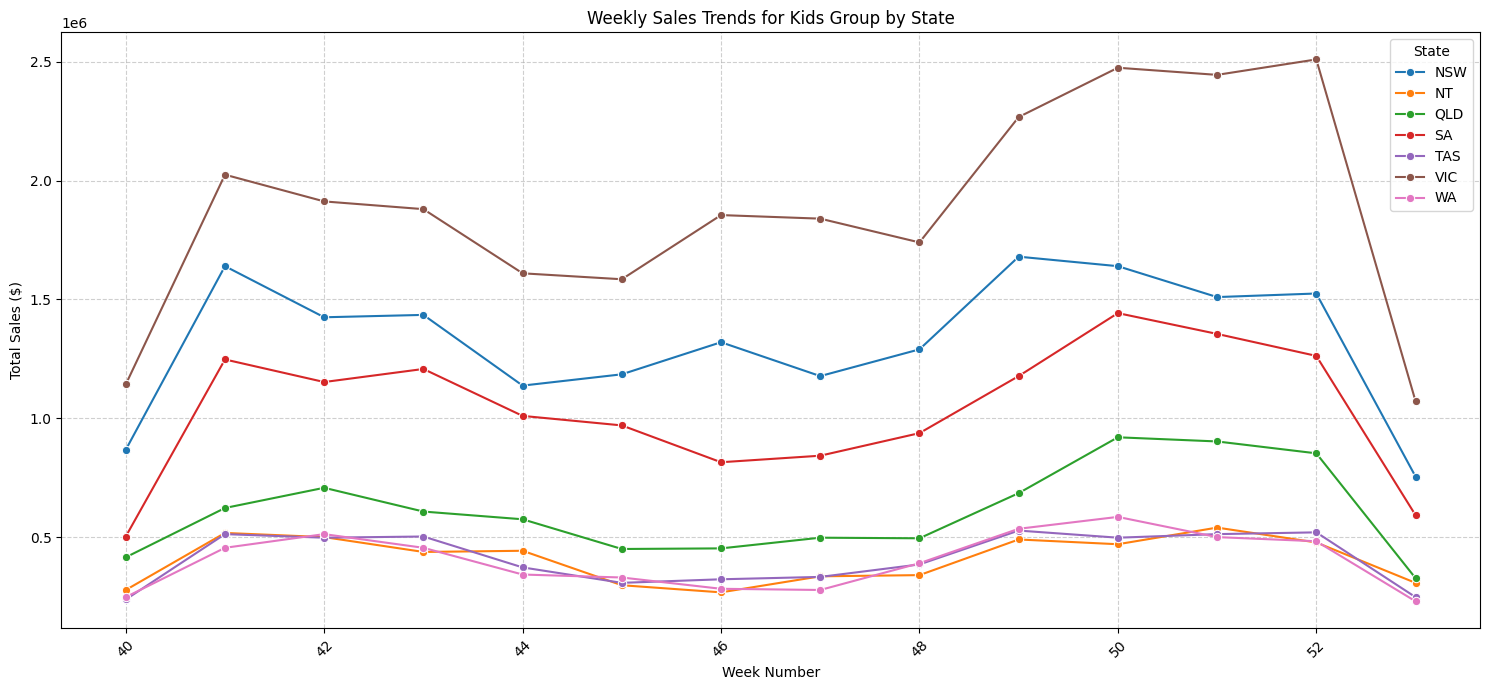

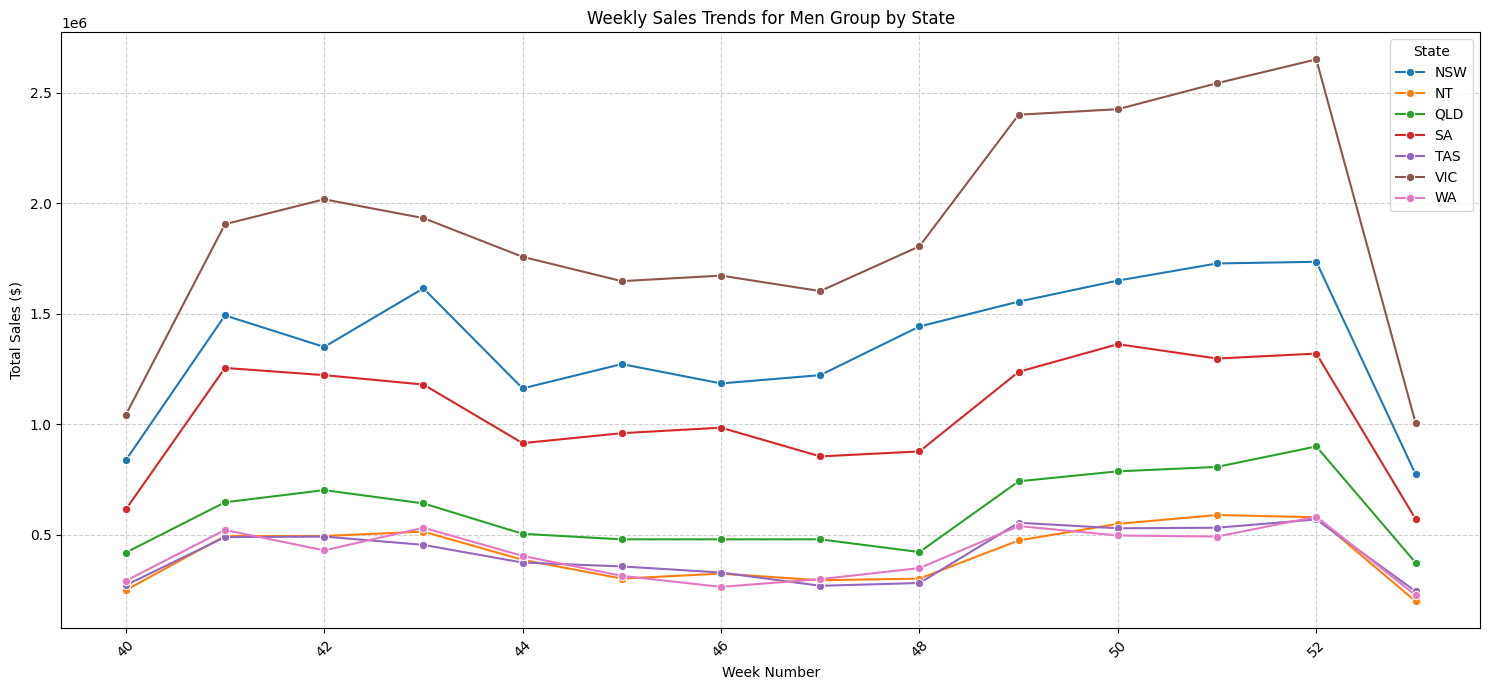

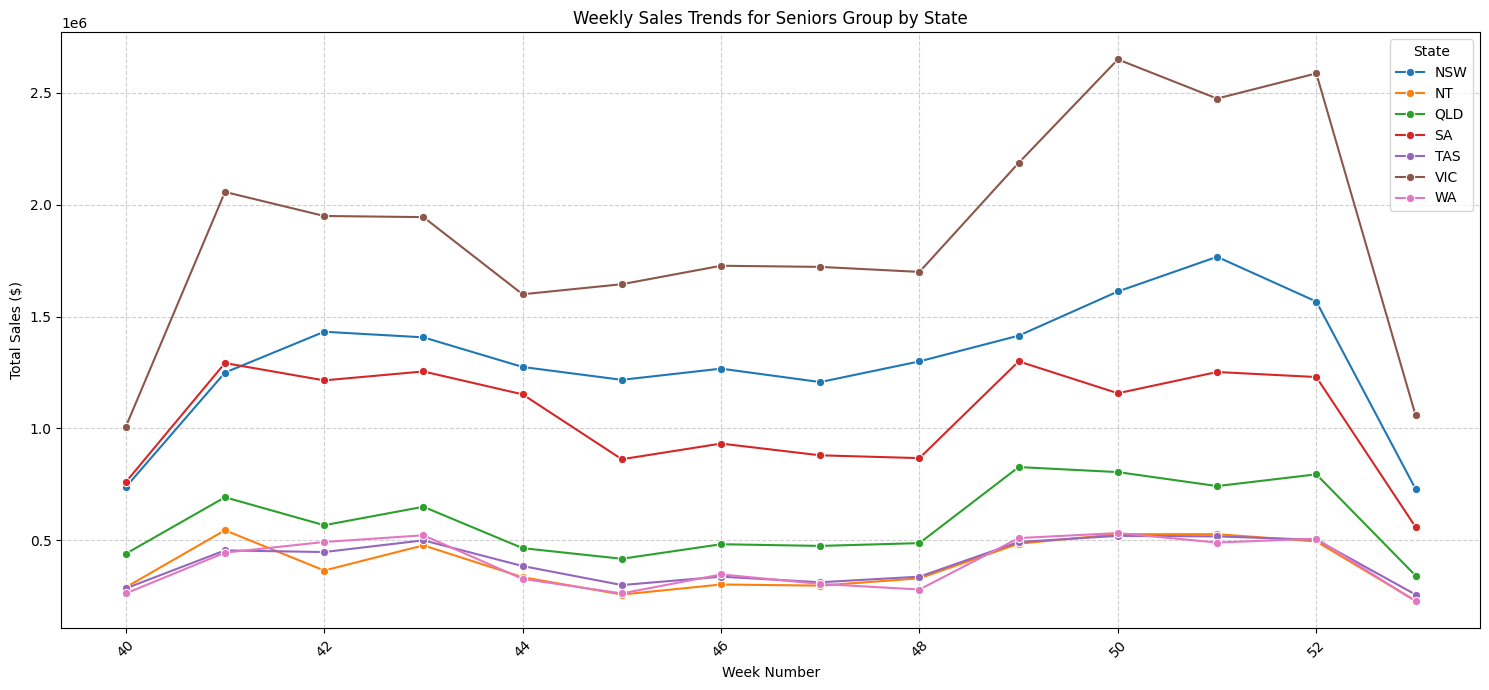

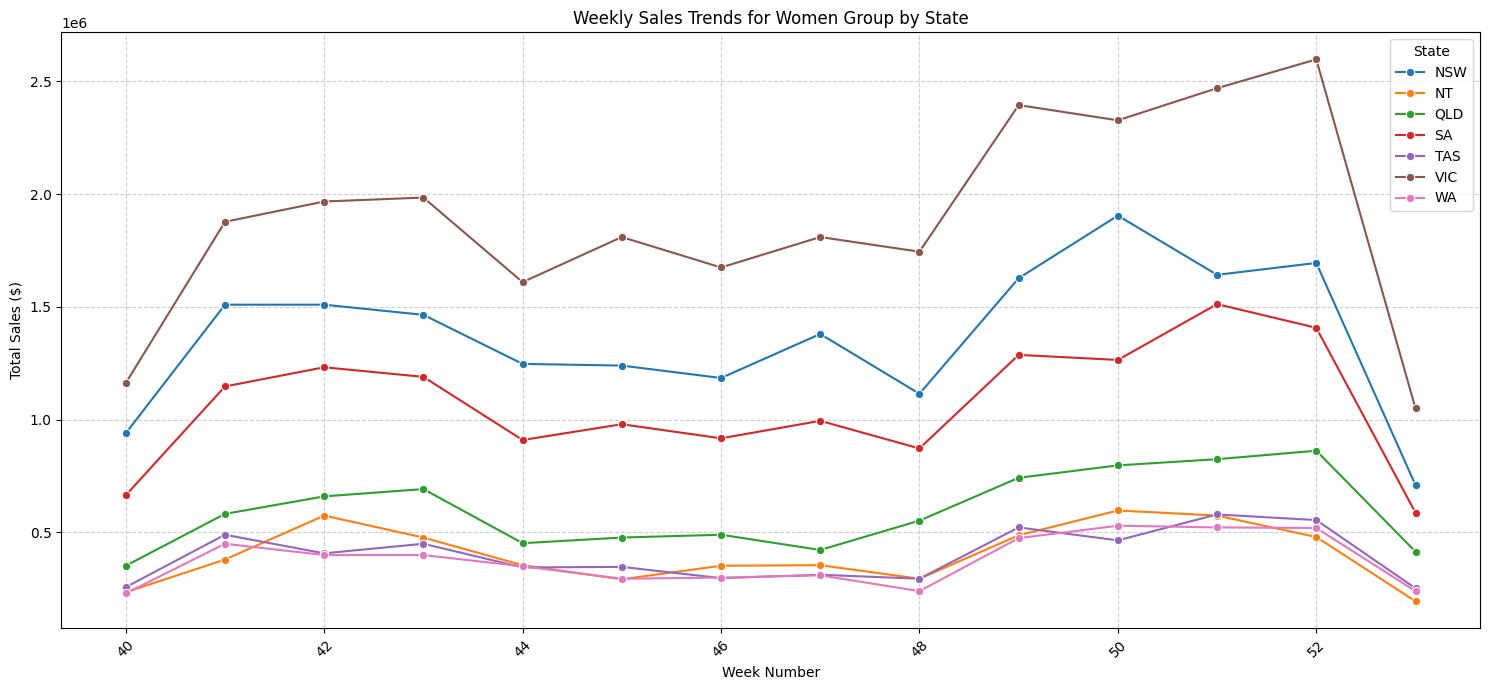

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get unique groups for iteration
groups = weekly_sales['Group'].unique()

# Iterate through each group and create a line plot for weekly sales by state
for group in groups:
    plt.figure(figsize=(15, 7))
    sns.lineplot(
        data=weekly_sales[weekly_sales['Group'] == group],
        x='Week',
        y='Total_Sales',
        hue='State',
        marker='o',
        palette='tab10'
    )
    plt.title(f'Weekly Sales Trends for {group} Group by State')
    plt.xlabel('Week Number')
    plt.ylabel('Total Sales ($)')
    plt.xticks(rotation=45) # Rotate x-axis labels for readability
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='State')
    plt.tight_layout()
    plt.show()


## Plot Monthly Sales by Group and State

### Subtask:
Generate line plots illustrating monthly sales trends for each demographic group, broken down by state, using the `monthly_sales` DataFrame. This will provide insights into monthly performance and variations.


**Reasoning**:
Generate line plots to visualize monthly sales trends for each demographic group across different states, as specified in the instructions. This will provide a clear overview of monthly performance patterns for each state within every group.



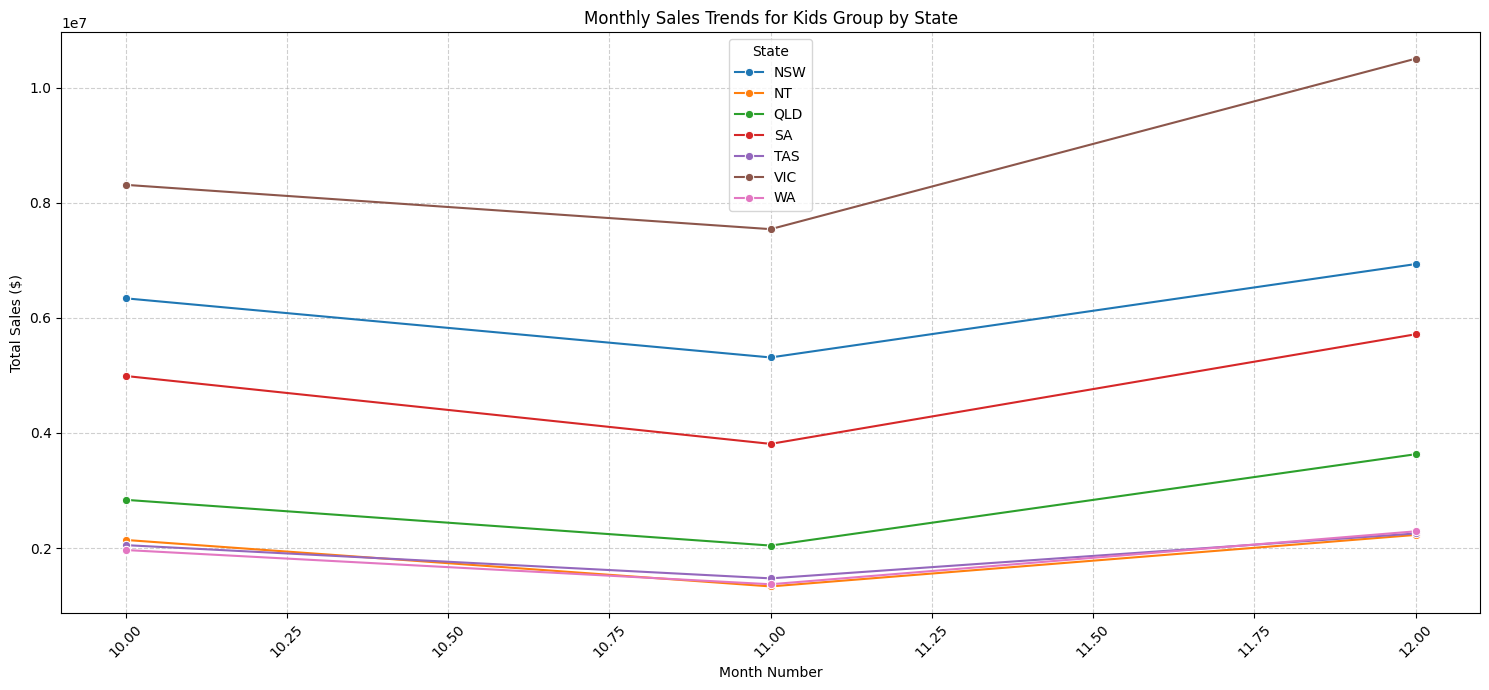

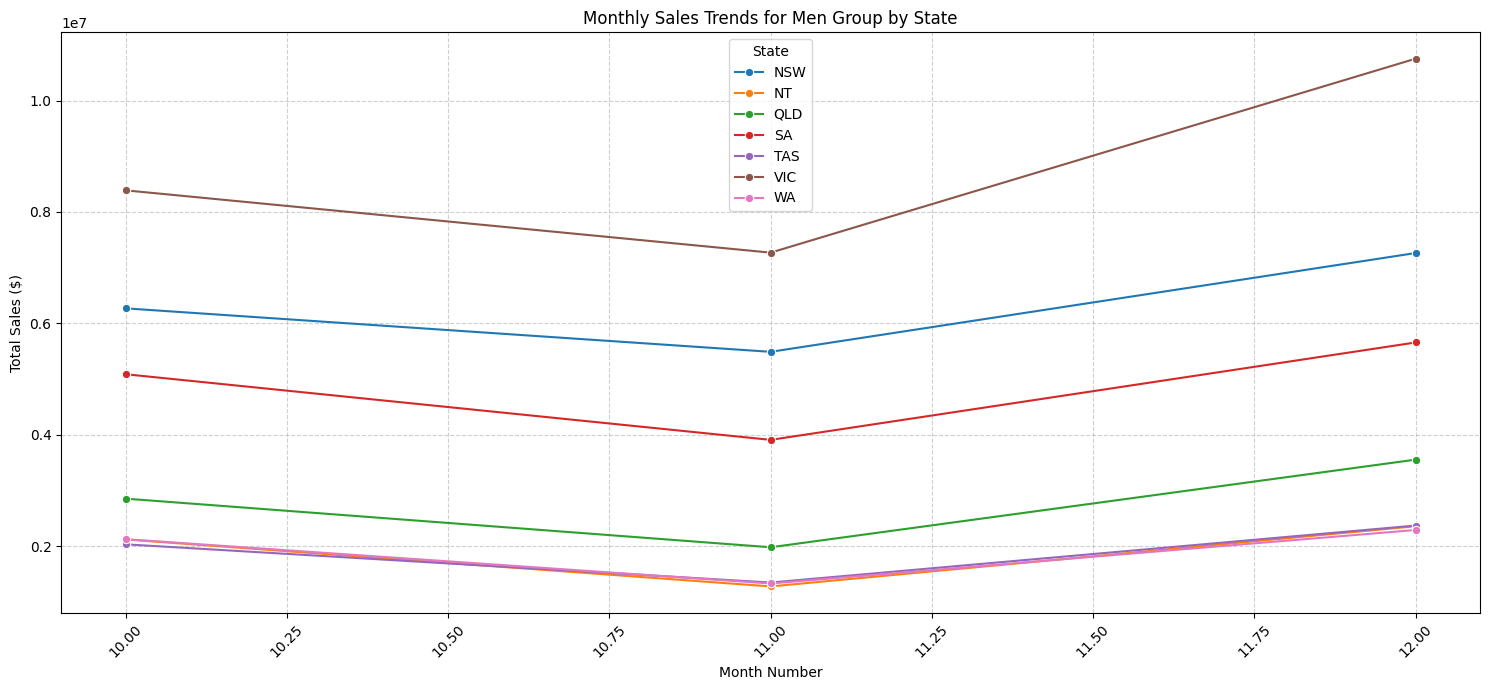

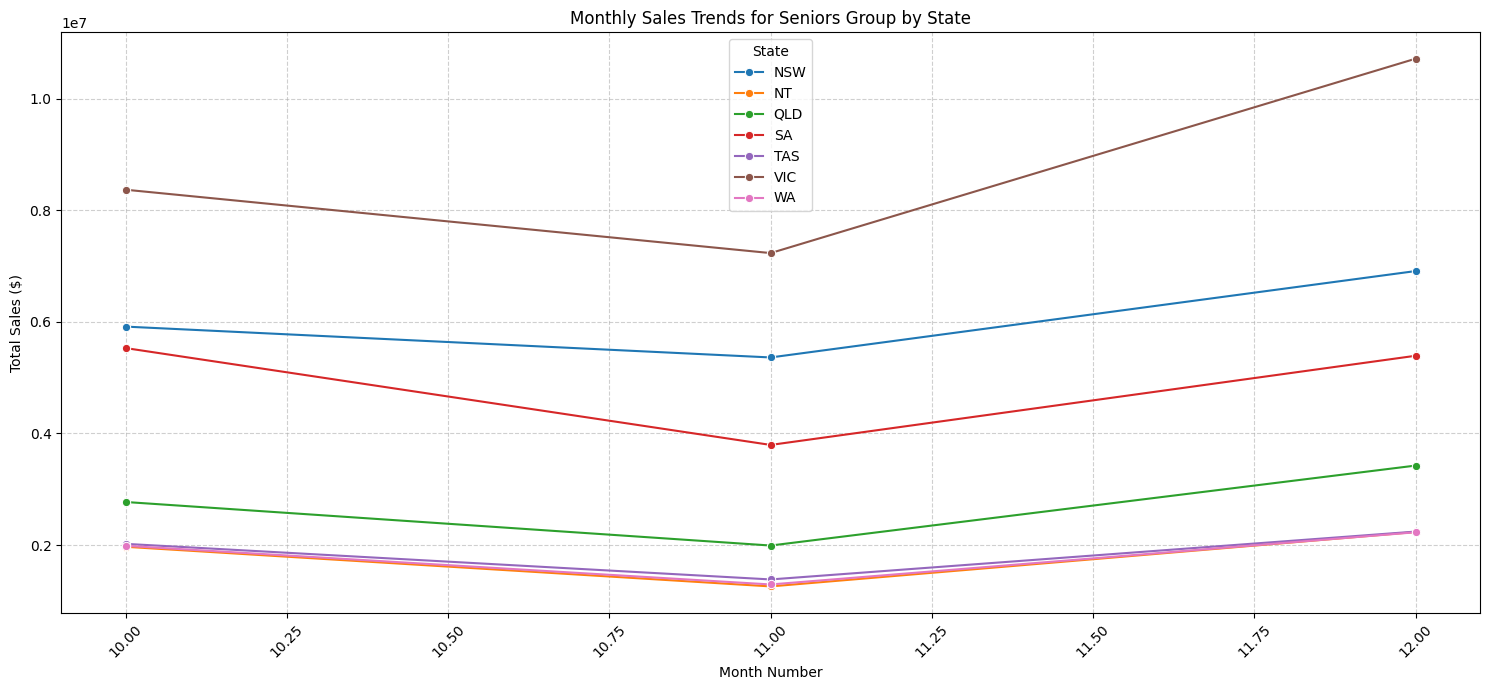

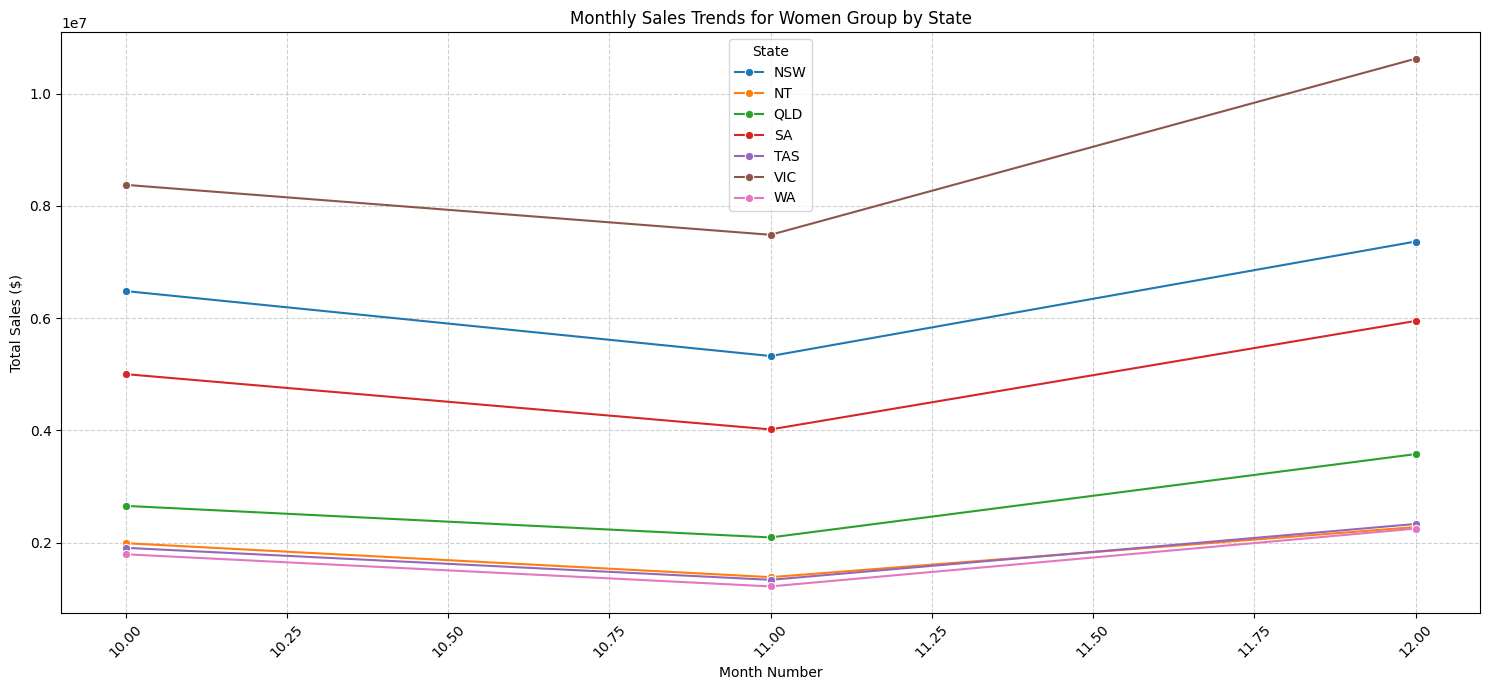

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get unique groups for iteration
groups = monthly_sales['Group'].unique()

# Iterate through each group and create a line plot for monthly sales by state
for group in groups:
    plt.figure(figsize=(15, 7))
    sns.lineplot(
        data=monthly_sales[monthly_sales['Group'] == group],
        x='Month',
        y='Total_Sales',
        hue='State',
        marker='o',
        palette='tab10'
    )
    plt.title(f'Monthly Sales Trends for {group} Group by State')
    plt.xlabel('Month Number')
    plt.ylabel('Total Sales ($)')
    plt.xticks(rotation=45) # Rotate x-axis labels for readability
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='State')
    plt.tight_layout()
    plt.show()

## Plot Quarterly Sales by Group and State

### Subtask:
Develop bar plots to display quarterly sales for each demographic group across different states, using the `quarterly_sales` DataFrame. This visualization will highlight overall quarterly performance and state-wise contributions.


**Reasoning**:
To visualize quarterly sales for each demographic group across different states, I will generate bar plots. This approach allows for a clear comparison of sales performance by state within each group for the quarter.



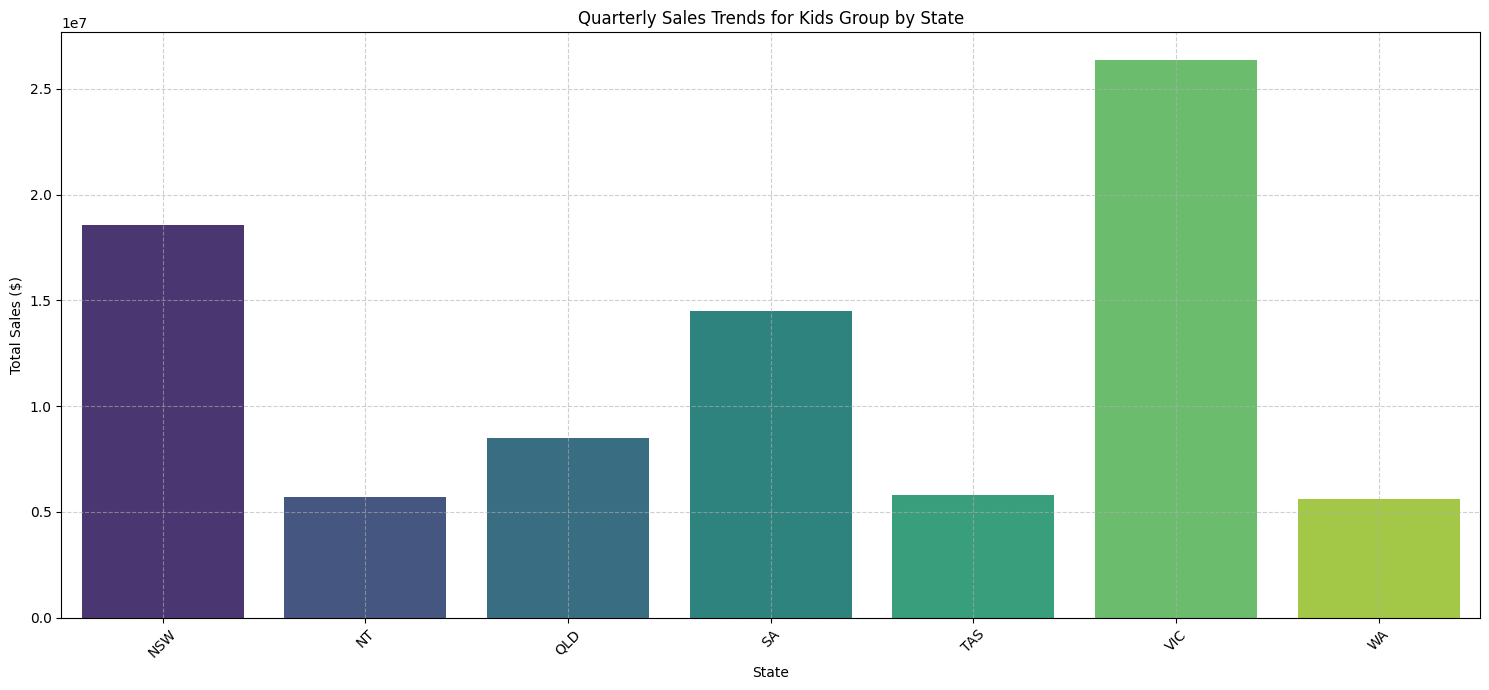

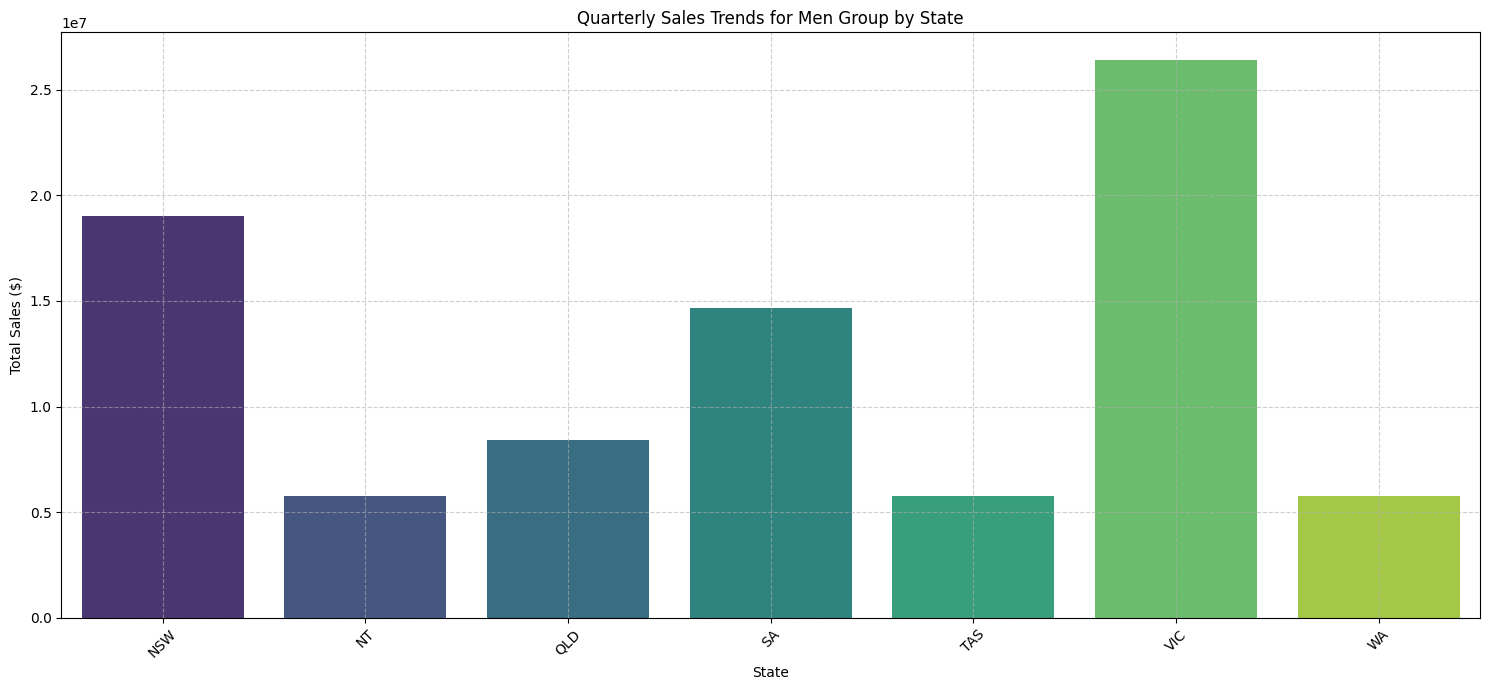

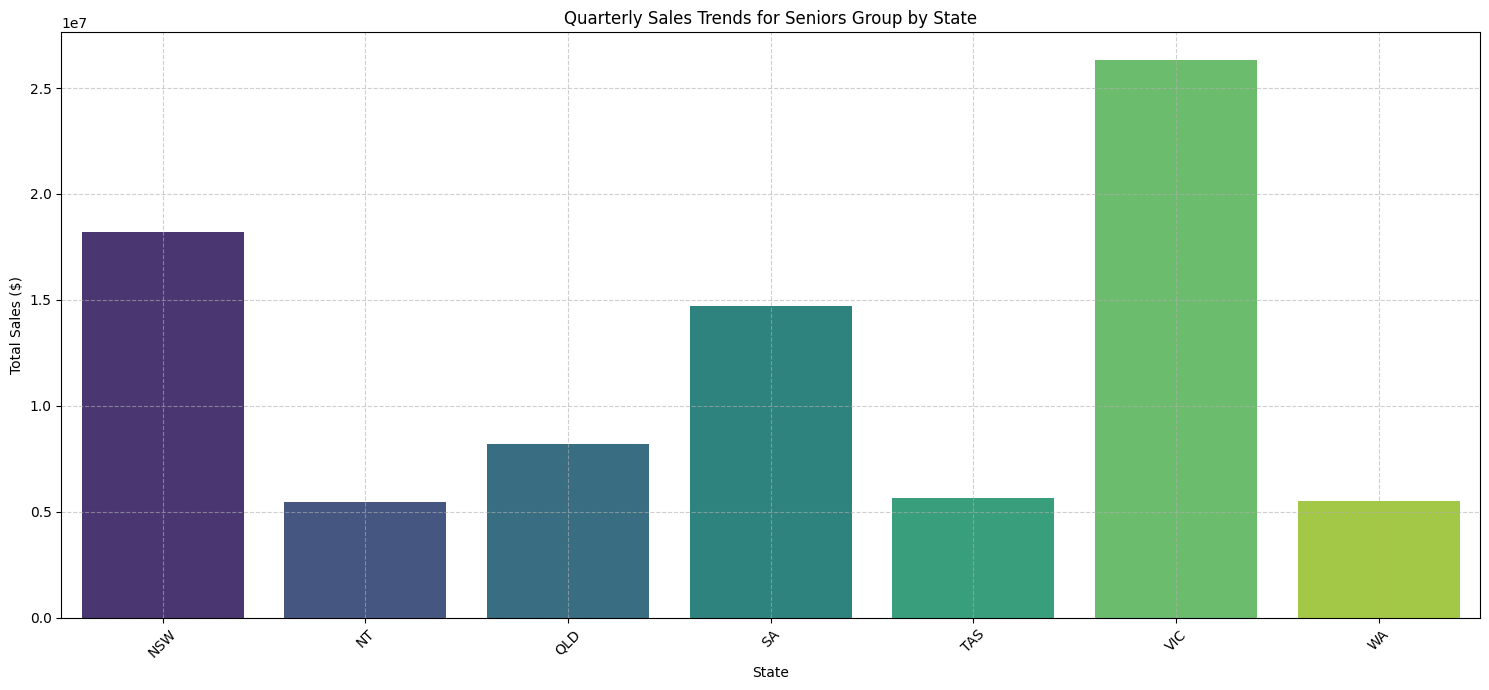

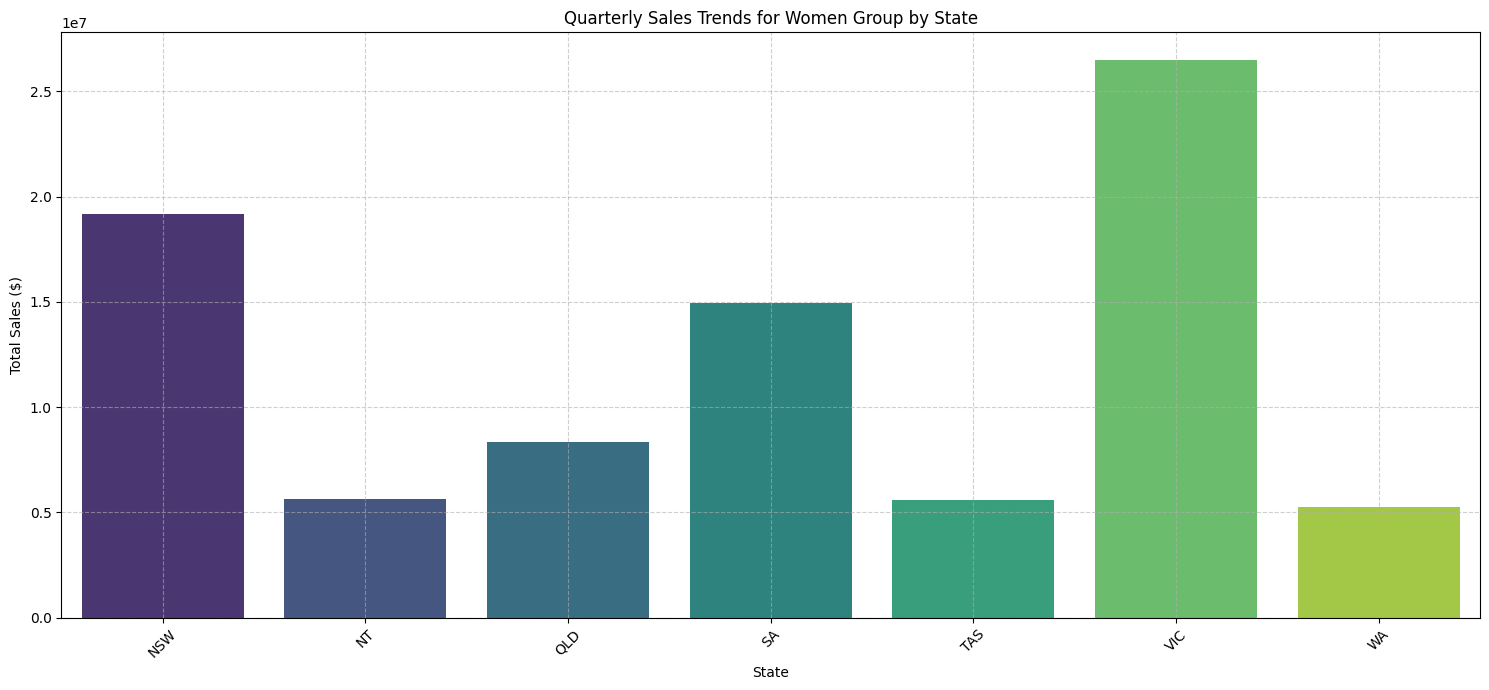

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get unique groups for iteration
groups = quarterly_sales['Group'].unique()

# Iterate through each group and create a bar plot for quarterly sales by state
for group in groups:
    plt.figure(figsize=(15, 7))
    sns.barplot(
        data=quarterly_sales[quarterly_sales['Group'] == group],
        x='State',
        y='Total_Sales',
        hue='State',
        palette='viridis',
        legend=False
    )
    plt.title(f'Quarterly Sales Trends for {group} Group by State')
    plt.xlabel('State')
    plt.ylabel('Total Sales ($)')
    plt.xticks(rotation=45) # Rotate x-axis labels for readability
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

## Final Task

### Subtask:
Provide a summary of the visualizations generated in cell `MKYn-L7p8kaO`, highlighting key insights about daily, weekly, monthly, and quarterly sales patterns for different demographic groups and states, and how this information can aid S&M teams.
